### Experimenting with PyTorch, version 1

This notebook uses the simple "Work experience years vs. Expected Salary" -dataset.

Just a simple linear model to try out basic features of PyTorch.

In [136]:
# basic way to install torch:
# pip install torch

# if you need GPU support for your PyTorch (only NVidia GPUs with CUDA-support are supported!):
# you can generate the needed pip install command here:
# https://pytorch.org/get-started/locally/

# e.g. something like this:
# pip3 install torch torchvision --index-url https://download.pytorch.org/whl/cu134

In [137]:
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt

df = pd.read_csv("Salary_Data.csv")
df

,YearsExperience,Salary
0,1.1,39343.0
1,1.3,46205.0
2,1.5,37731.0
3,2.0,43525.0
4,2.2,39891.0
5,2.9,56642.0
6,3.0,60150.0
7,3.2,54445.0
8,3.2,64445.0
9,3.7,57189.0


**First, X/y -splits and preprocess the data (numpy/tensors etc.)**

In [138]:
# typical X/y -split
X = df["YearsExperience"]
y = df["Salary"]

In [139]:
# data to NumPy -format 
X_numpy = np.array(list(X), dtype = np.float32)
y_numpy = np.array(list(y), dtype = np.float32)

In [140]:
# convert NumPy -data into the torch tensor format
X_torch = torch.tensor(X_numpy).unsqueeze(1)
y_torch = torch.tensor(y_numpy).unsqueeze(1)

In [141]:
# these shapes should match since we only have
# 1 support variable and 1 target variable
print(X_torch.shape)
print(y_torch.shape)

torch.Size([30, 1])
torch.Size([30, 1])


**Define the neural network structure**

In [142]:
import torch.nn as nn

# a very simple one layer linear structure
class LinearRegression(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer = nn.Linear(1,1)
        
    def forward(self, x_torch):
        return self.layer(x_torch)

In [143]:
# create model
model = LinearRegression()

# define loss-function and learning rate 
# optimizer => SGD (Stochastic Gradient Descent, 
# very similar to the one we used in the neural network from scratch)
loss_fn = nn.MSELoss()
learning_rate = 0.001
optimizer = torch.optim.SGD(params= model.parameters(), lr = learning_rate)

**Training loop in the PyTorch**

In [144]:
loss_list = []
epochs = 1000

# very similar to our neural network from scratch -version
for epoch in range(epochs):
    model.train()
    y_pred = model(X_torch)
    loss = loss_fn(y_pred, y_torch)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    # add loss to list for inspection (metrics)
    loss_list.append(loss.data)

    print('epoch {}, loss {}'.format(epoch, loss.data))
    
    model.eval()

epoch 0, loss 6502385152.0
epoch 1, loss 5602121216.0
epoch 2, loss 4829500928.0
epoch 3, loss 4166425600.0
epoch 4, loss 3597360896.0
epoch 5, loss 3108976128.0
epoch 6, loss 2689830400.0
epoch 7, loss 2330106368.0
epoch 8, loss 2021376768.0
epoch 9, loss 1756411392.0
epoch 10, loss 1529004032.0
epoch 11, loss 1333829120.0
epoch 12, loss 1166315776.0
epoch 13, loss 1022541696.0
epoch 14, loss 899140544.0
epoch 15, loss 793223360.0
epoch 16, loss 702310976.0
epoch 17, loss 624275520.0
epoch 18, loss 557291264.0
epoch 19, loss 499791136.0
epoch 20, loss 450430240.0
epoch 21, loss 408054272.0
epoch 22, loss 371672960.0
epoch 23, loss 340436000.0
epoch 24, loss 313614208.0
epoch 25, loss 290581440.0
epoch 26, loss 270800416.0
epoch 27, loss 253809920.0
epoch 28, loss 239214368.0
epoch 29, loss 226674176.0
epoch 30, loss 215897904.0
epoch 31, loss 206635328.0
epoch 32, loss 198671920.0
epoch 33, loss 191823472.0
epoch 34, loss 185931808.0
epoch 35, loss 180861408.0
epoch 36, loss 176495680

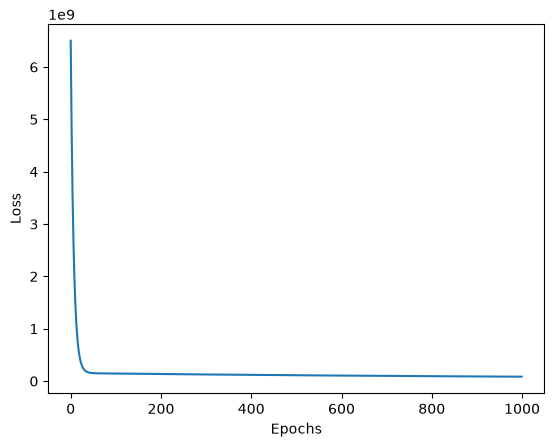

In [145]:
# We can plot the loss function and see how it changes with epochs. 
# The trend is that it should move downwwards and the loss should decrease
plt.plot(range(epochs),loss_list)
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.show()

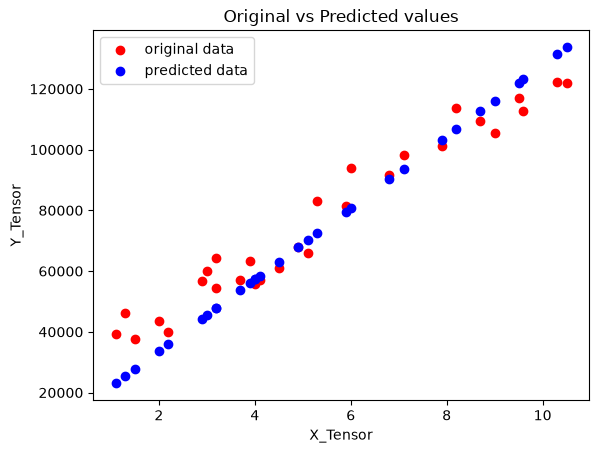

In [146]:
# Finally we can plot the predicted values alongside the actual values. 
# They should reflect a linear pattern and correlation between x and y. 
predicted = model(X_torch).data.numpy()
plt.scatter(X_torch, y_torch, label = "original data", color = "red")
plt.scatter(X_torch, predicted, label = "predicted data", color = "blue")

plt.legend()
plt.xlabel("X_Tensor")
plt.ylabel("Y_Tensor")
plt.title("Original vs Predicted values")
plt.show()

### Try the model in practice

In [147]:
years = 7

# compare these to the earlier part of the code where training data is processed
testing_numpy = np.array([years], dtype=np.float32)
testing_torch = torch.tensor(testing_numpy).unsqueeze(1)
predicted = model(testing_torch).data.numpy()

print(f"Salary: {predicted[0][0]} $")

Salary: 92547.9296875 $
